# Step 6 – Circular polarisation basis

The same measurement expressed with circular instead of linear (H, V) polarisation. For monostatic backscatter (Lee & Pottier 2009):

$$S_{RR} = jS_{HV} + \tfrac{1}{2}(S_{HH} - S_{VV}), \qquad S_{LL} = jS_{HV} - \tfrac{1}{2}(S_{HH} - S_{VV}), \qquad S_{RL} = \tfrac{j}{2}(S_{HH} + S_{VV})$$

which is $\mathbf{S}_{circ} = \mathbf{U}^T\mathbf{S}\,\mathbf{U}$ (not $\mathbf{U}\mathbf{S}\mathbf{U}^H$, which is only valid for forward scattering). The code checks the convention on two known targets: a flat surface gives only $S_{RL}$, a dihedral only $S_{RR}$ and $S_{LL}$.

Four maps per scene, averaged over a window (multilook):

| Map | Formula | Meaning |
|---|---|---|
| CPR | $\dfrac{\langle\lvert S_{RR}\rvert^2\rangle + \langle\lvert S_{LL}\rvert^2\rangle}{2\langle\lvert S_{RL}\rvert^2\rangle}$ | circular polarisation ratio = (Pauli red + green) / blue: ≈ 0 for surface scattering, high (towards or above 1) for volume / multiple scattering in firn and ice |
| RR–LL coherence | $\lvert\rho_{RRLL}\rvert = \dfrac{\lvert\langle S_{RR}S_{LL}^*\rangle\rvert}{\sqrt{\langle\lvert S_{RR}\rvert^2\rangle\langle\lvert S_{LL}\rvert^2\rangle}}$ | how consistent the RR–LL relation is (roughness, structure); also the reliability of the RR–LL phase |
| RR–LL phase | $\phi_{RRLL} = \arg\langle S_{RR}S_{LL}^*\rangle$, −180° … 180° | sensitive to aligned ice crystals (anisotropic fabric) and to tilted scatterers |
| HH–VV phase | $\phi_{HHVV} = \arg\langle S_{HH}S_{VV}^*\rangle$, −180° … 180° | co-polar phase difference, the standard measure of ice/snow fabric anisotropy (birefringence) |

Phases are shown in grey where their coherence ($\lvert\rho_{RRLL}\rvert$ or $\lvert\rho_{HHVV}\rvert$) is below 0.3: there they are noise.

**Why the phases matter for ice.** Ice with aligned crystals is birefringent: waves polarised along and across the crystal alignment travel at slightly different speeds, which creates a phase difference between the channels.
- $\phi_{HHVV}$: ≈ 0° for isotropic ice and untilted surfaces; a systematic deviation points to birefringence (aligned crystals).
- $\phi_{RRLL}$: with $D = \tfrac12(S_{HH}-S_{VV})$, $\langle S_{RR}S_{LL}^*\rangle = \langle\lvert S_{HV}\rvert^2\rangle - \langle\lvert D\rvert^2\rangle - 2j\,\mathrm{Re}\langle S_{HV}D^*\rangle$. The phase is ≈ ±180° where HH−VV dominates over HV, ≈ 0° where HV dominates (common over ice with HH ≈ VV), and in between (towards ±90°) where HV and HH−VV are correlated – the part related to alignment / orientation. Read it together with $\phi_{HHVV}$ and the coherence.

**Relation to the orientation angle.** The polarisation orientation angle used for terrain slopes (Lee et al. 2000) is the same RR–LL phase, rescaled: $\theta = \tfrac{1}{4}[\phi_{RRLL} + \pi]$, wrapped to ±45°. It assumes the phase comes from a tilt, which is not the right reading for ice fabric, so it is not shown as a map but kept in the GeoTIFF.

Rotations of the polarisation (e.g. residual Faraday rotation at P-band) only change the phase of $S_{RR}$ and $S_{LL}$, so the CPR is robust against them.

Results per scene: `<product>_circular.png`, and a 6-band `.tif` (CPR, RR–LL coherence, RR–LL phase, HH–VV coherence, HH–VV phase, orientation angle).
**Output folders**: every run gets its own folder with a time stamp, so earlier results are never overwritten. Inside it, the folders mirror the input folders, so every result can be traced back to its product:
`<OUTPUT_DIR>/<date_time>_<analysis>[_<label>]/<stack folder>/L1C/<product>/<product>_<analysis>.png` (and `.tif`).
Each run folder has a `run_info.json` (settings and scenes of the run), and each stack folder a `stack_info.json` (stack ID, primary, what has been processed).

**How to use**
0. First time only: run **6.0** to install the packages, then restart the kernel.
1. Set `DATA_DIR` and `OUTPUT_DIR` in **6.1**, then run **6.1** and **6.2**: they load the tools and list all stacks (with their stack ID) and scenes (★ = primary).
2. Fill in **6.3 Settings**: which stacks and scenes to process.
3. Run **6.4**.

`BiomassProduct.py` (ESA) and `polsar_utils.py` must be in the same folder as this notebook.

## 6.0 First time only: install the packages
Run once, then restart the kernel (**Kernel → Restart Kernel**). `--user` installs them in your home folder, so they are kept when the server restarts. Skip this cell if 6.1 runs without errors.

In [1]:
%pip install --user netCDF4 xarray folium shapely pillow

Note: you may need to restart the kernel to use updated packages.


## 6.1 Load the tools and choose the folders
- `DATA_DIR`: the folder that contains your stacks. It can be a folder on your computer or a cloud bucket mounted as a folder. Leave it as `None` to search automatically.
- `OUTPUT_DIR`: the main folder for all results. It is created if it does not exist; `~` is your home folder.

In [10]:
%matplotlib inline
import polsar_utils as pu

DATA_DIR = "/home/jovyan/shared-buckets/6e08893c-463e-498b-92d2-6761dd17160d/biomass_inputs"  # e.g. "/path/to/biomass_inputs"; None = search automatically
OUTPUT_DIR = "/home/jovyan/idas_dump/test/Wilkens"  # main folder for all result

## 6.2 Overview of the data

In [11]:
stacks = pu.find_stacks(DATA_DIR)
pu.print_overview(stacks)

7 stack(s), 49 scene(s)

[0] BIO_S1_STA__ID_20260915T214352_20261003T214425_T_G01_M05_S0720_W0730_D_02_DZ1NQJ  (7 scenes)
      [0] 2026-09-15 21:43             BIO_S1_STA__1S_20260915T214352_20260915T214412_T_G01_M05_C01_T028_F218_02_DZ1QL2
      [1] 2026-09-18 21:43             BIO_S1_STA__1S_20260918T214354_20260918T214414_T_G01_M05_C02_T028_F218_02_DZ1QLP
      [2] 2026-09-21 21:43             BIO_S1_STA__1S_20260921T214356_20260921T214417_T_G01_M05_C03_T028_F218_02_DZ1QMC
      [3] 2026-09-24 21:43  ★ primary  BIO_S1_STA__1S_20260924T214358_20260924T214419_T_G01_M05_C04_T028_F218_02_DZ1QMU
      [4] 2026-09-27 21:44             BIO_S1_STA__1S_20260927T214401_20260927T214421_T_G01_M05_C05_T028_F218_02_DZ1QNE
      [5] 2026-09-30 21:44             BIO_S1_STA__1S_20260930T214403_20260930T214423_T_G01_M05_C06_T028_F218_02_DZ1QO2
      [6] 2026-10-03 21:44             BIO_S1_STA__1S_20261003T214405_20261003T214425_T_G01_M05_C07_T028_F218_02_DZ1QOO
[1] BIO_S2_STA__ID_20260514T160710_202

## 6.3 Settings
**Which data**
- `STACKS`: `"all"`, stack names such as `["stack_01", "stack_20"]`, stack IDs (the full ID or just its end, e.g. `["DZ1NQJ"]`), or numbers from the list in 6.2 such as `[0, 2]`
- `SCENES`: `"all"`, `"primary"` (only the primary of each stack), dates such as `["2026-09-15"]`, or numbers within each stack such as `[0, 3]`

Numbers start at 0, as in the list in 6.2.

**Where the results go** (inside `OUTPUT_DIR` from 6.1)
- `NEW_RUN_FOLDER`: `True` = a new folder with a time stamp for every run (nothing is overwritten); `False` = write directly in `OUTPUT_DIR`
- `RUN_LABEL`: optional name added to the run folder, e.g. `"window200"`
- `SKIP_EXISTING`: only used when `NEW_RUN_FOLDER = False`: skip scenes that already have a result there (and show the saved result)

**Processing**
- `WINDOW_M`: averaging window in metres (100 m gives ~50 looks with BIOMASS)
- `HHVV_PHASE_RANGE`: colour scale of the HH–VV phase map, `"auto"` (zooms in to the actual range, e.g. ±10°, so small deviations are visible) or a number such as `20` for ±20°
- `SAVE_GEOTIFF`: also save a GeoTIFF

In [12]:
STACKS = ["DZ1NSW"]
SCENES = "all"

NEW_RUN_FOLDER = True
RUN_LABEL = "window100"
WINDOW_M = 100
HHVV_PHASE_RANGE = "auto"
SAVE_GEOTIFF = True
SKIP_EXISTING = True
SHOW_FIGURES = True

## 6.4 Run

Selected 7 scene(s) in 1 stack(s):
   stack_02 | 2026-09-15 21:43 | BIO_S1_STA__1S_20260915T214333_20260915T214353_T_G01_M05_C01_T028_F217_02_DZ1QYS
   stack_02 | 2026-09-18 21:43 | BIO_S1_STA__1S_20260918T214335_20260918T214355_T_G01_M05_C02_T028_F217_02_DZ1QZF
   stack_02 | 2026-09-21 21:43 | BIO_S1_STA__1S_20260921T214337_20260921T214358_T_G01_M05_C03_T028_F217_02_DZ1R01
   stack_02 | 2026-09-24 21:43  ★ primary | BIO_S1_STA__1S_20260924T214339_20260924T214400_T_G01_M05_C04_T028_F217_02_DZ1R0K
   stack_02 | 2026-09-27 21:43 | BIO_S1_STA__1S_20260927T214341_20260927T214402_T_G01_M05_C05_T028_F217_02_DZ1R14
   stack_02 | 2026-09-30 21:43 | BIO_S1_STA__1S_20260930T214344_20260930T214404_T_G01_M05_C06_T028_F217_02_DZ1R1R
   stack_02 | 2026-10-03 21:43 | BIO_S1_STA__1S_20261003T214346_20261003T214406_T_G01_M05_C07_T028_F217_02_DZ1R2J
New run folder: /home/jovyan/idas_dump/test/Wilkens/2026-10-15_132401_circular_window100

[1/7] stack_02 | 2026-09-15 21:43 | BIO_S1_STA__1S_20260915T214333

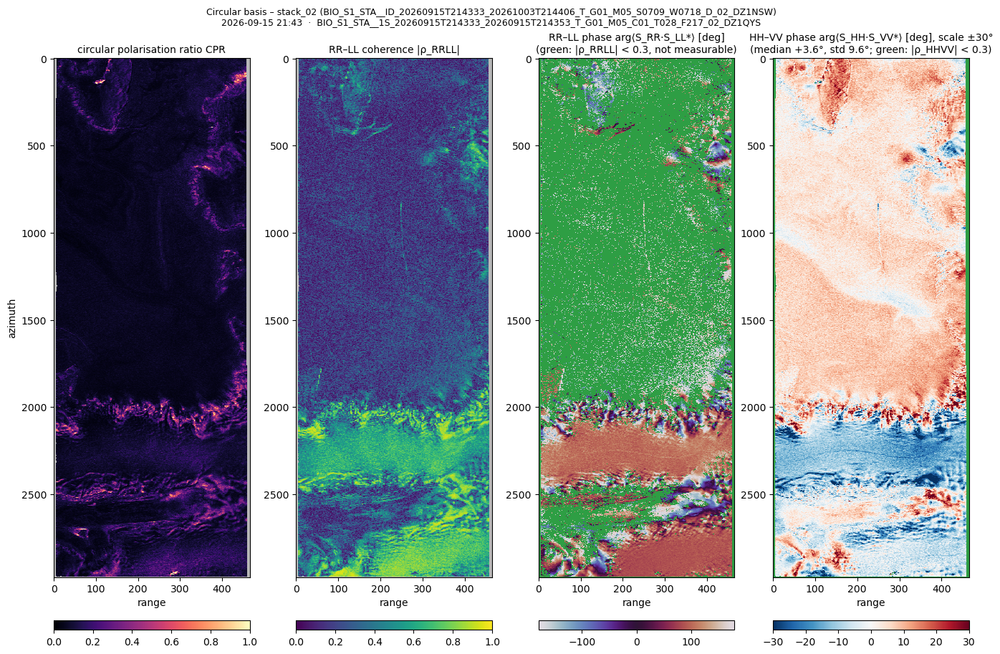

  saved BIO_S1_STA__1S_20260915T214333_20260915T214353_T_G01_M05_C01_T028_F217_02_DZ1QYS_circular.png
  saved BIO_S1_STA__1S_20260915T214333_20260915T214353_T_G01_M05_C01_T028_F217_02_DZ1QYS_circular.tif

[2/7] stack_02 | 2026-09-18 21:43 | BIO_S1_STA__1S_20260918T214335_20260918T214355_T_G01_M05_C02_T028_F217_02_DZ1QZF
  image 20820 x 931 (azimuth x range), valid pixels 97.0%, phase stored in radians
  checks: |corr(HV,VH)| 0.96, HV/VH -0.00 dB, HH-VV phase +4.8°, |corr(HH,VV)| 0.92
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  median CPR 0.07, mean |ρ_RRLL| 0.32, mean |ρ_HHVV| 0.91; phases shown in 37% (RR-LL) and 97% (HH-VV) of the pixels


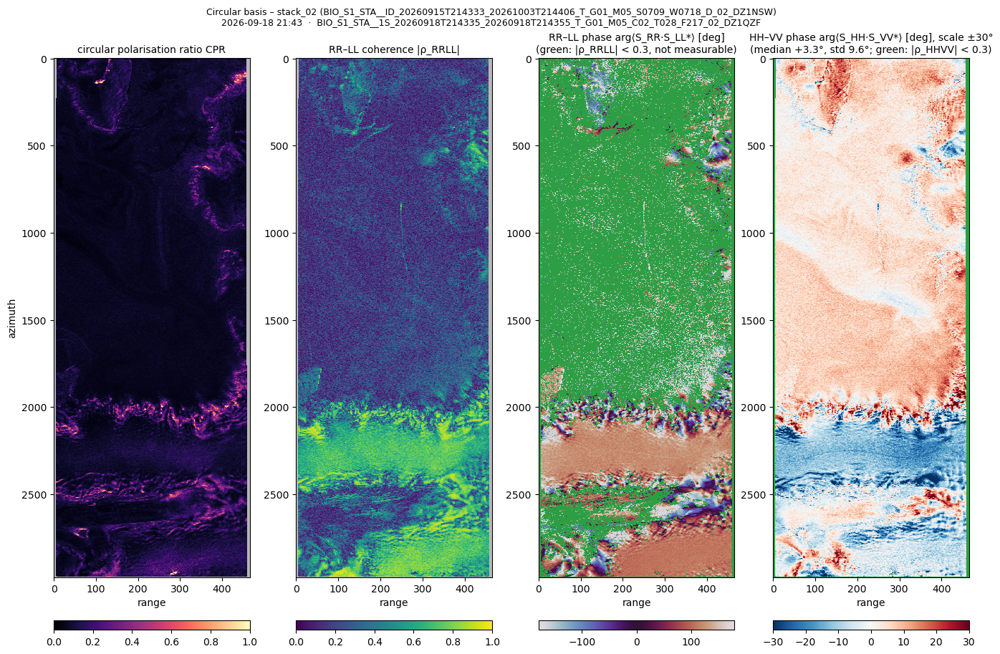

  saved BIO_S1_STA__1S_20260918T214335_20260918T214355_T_G01_M05_C02_T028_F217_02_DZ1QZF_circular.png
  saved BIO_S1_STA__1S_20260918T214335_20260918T214355_T_G01_M05_C02_T028_F217_02_DZ1QZF_circular.tif

[3/7] stack_02 | 2026-09-21 21:43 | BIO_S1_STA__1S_20260921T214337_20260921T214358_T_G01_M05_C03_T028_F217_02_DZ1R01
  image 20820 x 931 (azimuth x range), valid pixels 97.0%, phase stored in radians
  checks: |corr(HV,VH)| 0.96, HV/VH -0.02 dB, HH-VV phase +4.8°, |corr(HH,VV)| 0.92
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  median CPR 0.07, mean |ρ_RRLL| 0.32, mean |ρ_HHVV| 0.91; phases shown in 38% (RR-LL) and 97% (HH-VV) of the pixels


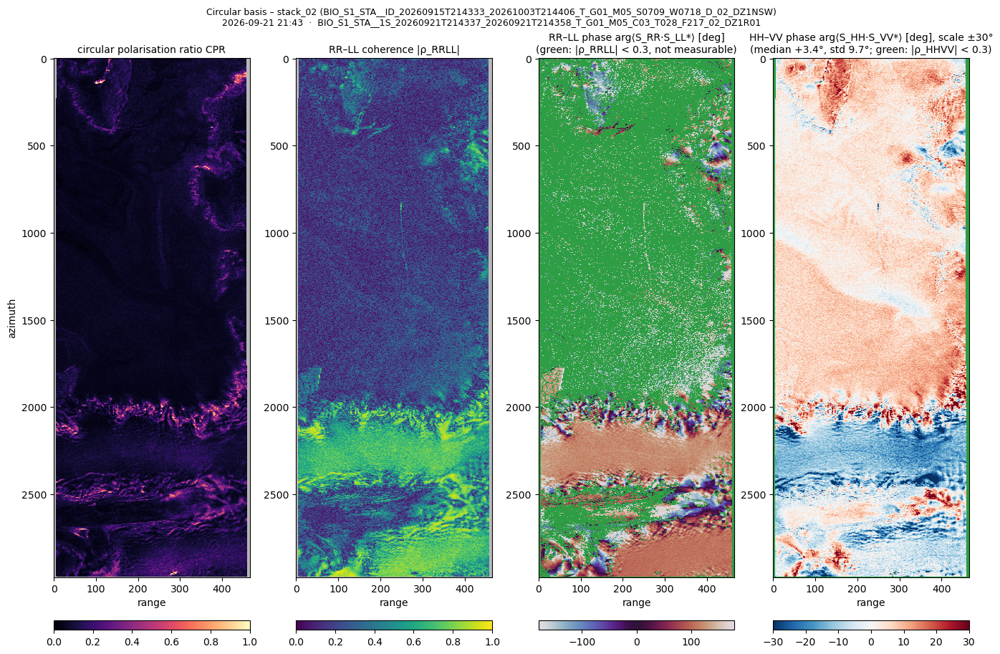

  saved BIO_S1_STA__1S_20260921T214337_20260921T214358_T_G01_M05_C03_T028_F217_02_DZ1R01_circular.png
  saved BIO_S1_STA__1S_20260921T214337_20260921T214358_T_G01_M05_C03_T028_F217_02_DZ1R01_circular.tif

[4/7] stack_02 | 2026-09-24 21:43  ★ primary | BIO_S1_STA__1S_20260924T214339_20260924T214400_T_G01_M05_C04_T028_F217_02_DZ1R0K
  image 20820 x 931 (azimuth x range), valid pixels 97.0%, phase stored in radians
  checks: |corr(HV,VH)| 0.96, HV/VH -0.01 dB, HH-VV phase +4.9°, |corr(HH,VV)| 0.93
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  median CPR 0.07, mean |ρ_RRLL| 0.31, mean |ρ_HHVV| 0.92; phases shown in 36% (RR-LL) and 97% (HH-VV) of the pixels


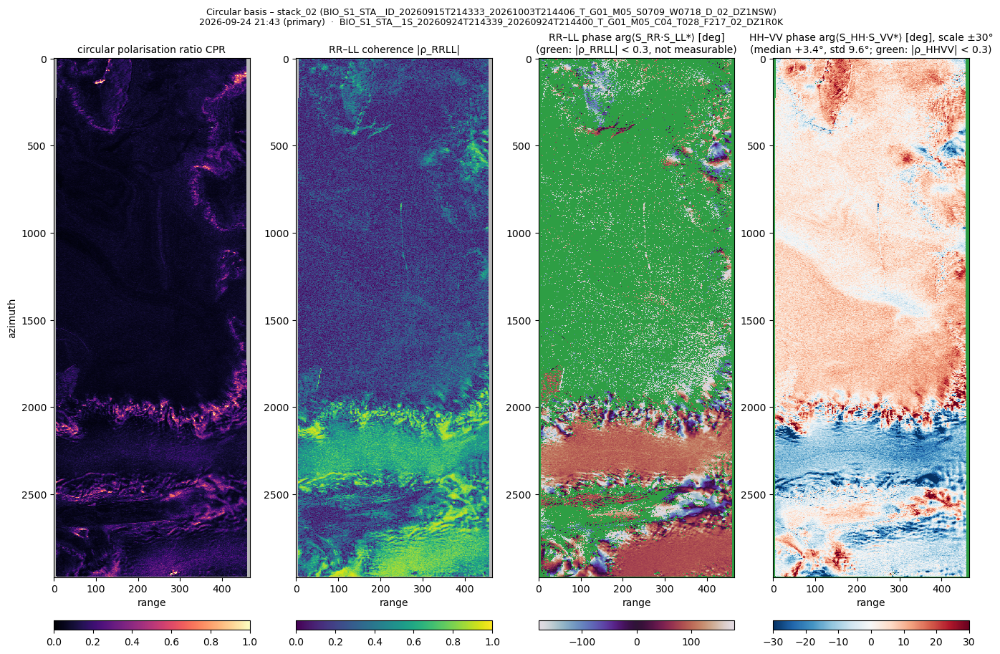

  saved BIO_S1_STA__1S_20260924T214339_20260924T214400_T_G01_M05_C04_T028_F217_02_DZ1R0K_circular.png
  saved BIO_S1_STA__1S_20260924T214339_20260924T214400_T_G01_M05_C04_T028_F217_02_DZ1R0K_circular.tif

[5/7] stack_02 | 2026-09-27 21:43 | BIO_S1_STA__1S_20260927T214341_20260927T214402_T_G01_M05_C05_T028_F217_02_DZ1R14
  image 20820 x 931 (azimuth x range), valid pixels 97.0%, phase stored in radians
  checks: |corr(HV,VH)| 0.96, HV/VH -0.01 dB, HH-VV phase +4.8°, |corr(HH,VV)| 0.92
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  median CPR 0.07, mean |ρ_RRLL| 0.31, mean |ρ_HHVV| 0.91; phases shown in 37% (RR-LL) and 97% (HH-VV) of the pixels


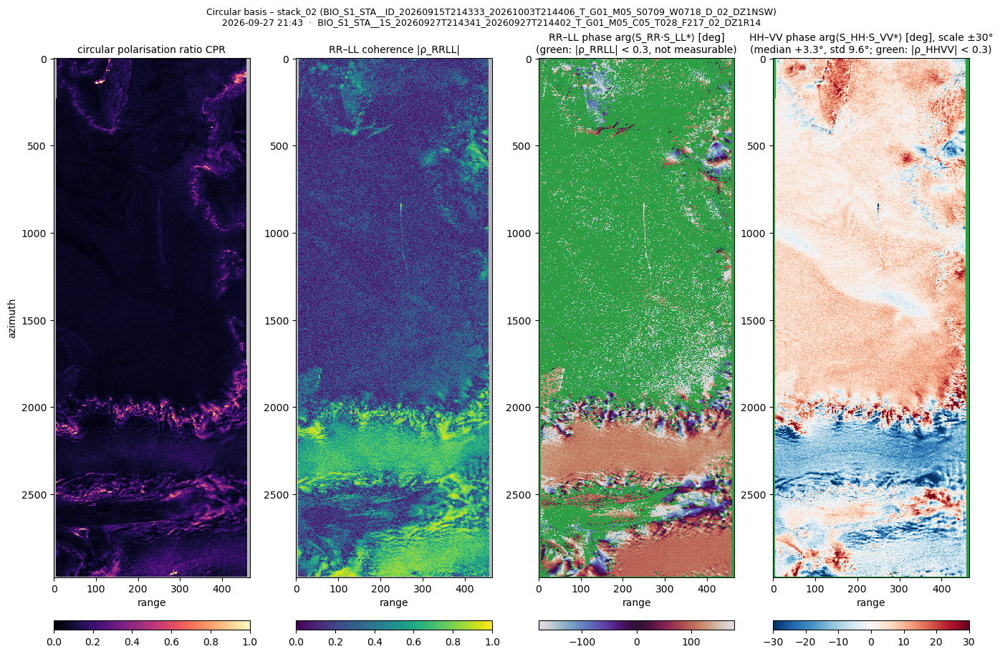

  saved BIO_S1_STA__1S_20260927T214341_20260927T214402_T_G01_M05_C05_T028_F217_02_DZ1R14_circular.png
  saved BIO_S1_STA__1S_20260927T214341_20260927T214402_T_G01_M05_C05_T028_F217_02_DZ1R14_circular.tif

[6/7] stack_02 | 2026-09-30 21:43 | BIO_S1_STA__1S_20260930T214344_20260930T214404_T_G01_M05_C06_T028_F217_02_DZ1R1R
  image 20820 x 931 (azimuth x range), valid pixels 97.0%, phase stored in radians
  checks: |corr(HV,VH)| 0.96, HV/VH -0.02 dB, HH-VV phase +4.9°, |corr(HH,VV)| 0.92
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  median CPR 0.07, mean |ρ_RRLL| 0.32, mean |ρ_HHVV| 0.91; phases shown in 38% (RR-LL) and 97% (HH-VV) of the pixels


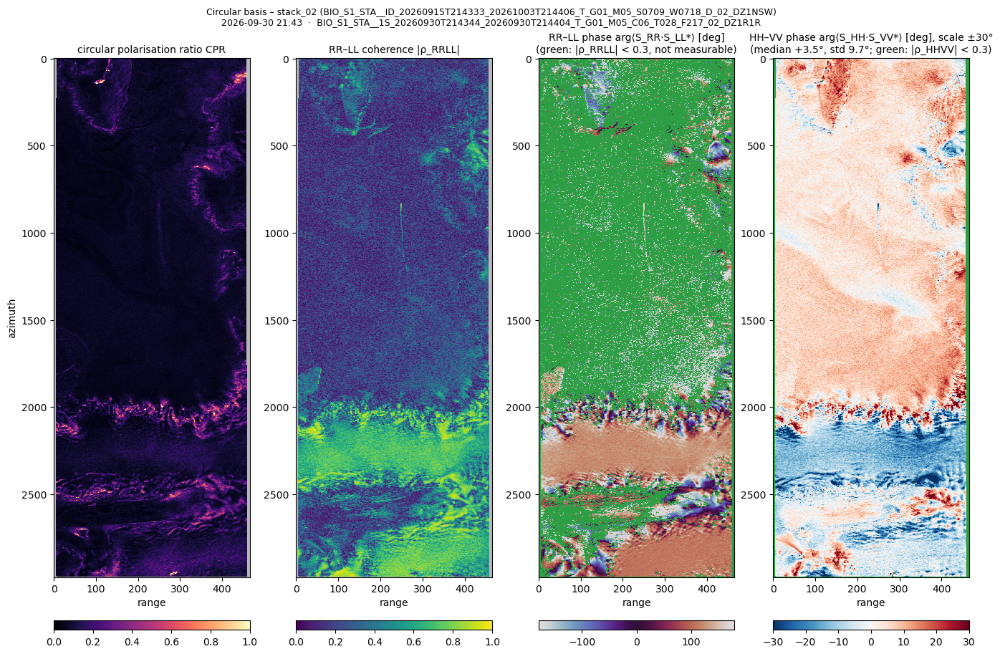

  saved BIO_S1_STA__1S_20260930T214344_20260930T214404_T_G01_M05_C06_T028_F217_02_DZ1R1R_circular.png
  saved BIO_S1_STA__1S_20260930T214344_20260930T214404_T_G01_M05_C06_T028_F217_02_DZ1R1R_circular.tif

[7/7] stack_02 | 2026-10-03 21:43 | BIO_S1_STA__1S_20261003T214346_20261003T214406_T_G01_M05_C07_T028_F217_02_DZ1R2J
  image 20820 x 931 (azimuth x range), valid pixels 97.0%, phase stored in radians
  checks: |corr(HV,VH)| 0.96, HV/VH -0.02 dB, HH-VV phase +5.1°, |corr(HH,VV)| 0.92
  multilook window 15 x 5 pixels (~100 m), ~50 looks
  median CPR 0.07, mean |ρ_RRLL| 0.32, mean |ρ_HHVV| 0.91; phases shown in 38% (RR-LL) and 97% (HH-VV) of the pixels


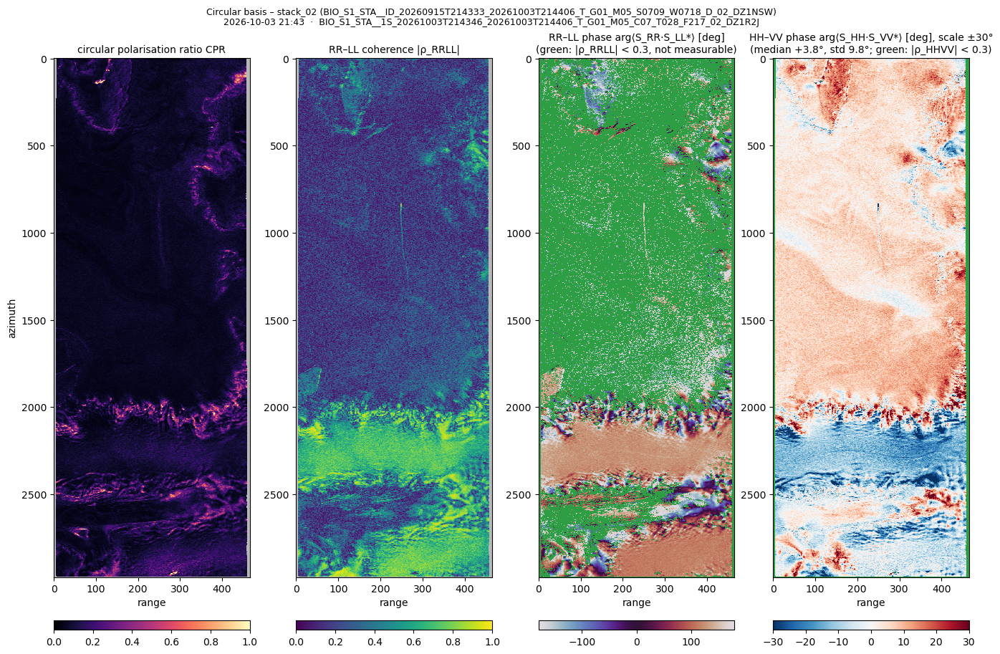

  saved BIO_S1_STA__1S_20261003T214346_20261003T214406_T_G01_M05_C07_T028_F217_02_DZ1R2J_circular.png
  saved BIO_S1_STA__1S_20261003T214346_20261003T214406_T_G01_M05_C07_T028_F217_02_DZ1R2J_circular.tif

Finished: 7 processed, 0 already done, 0 failed. Results in /home/jovyan/idas_dump/test/Wilkens/2026-10-15_132401_circular_window100


[]

In [13]:
scenes = pu.select_scenes(stacks, STACKS, SCENES)
run_dir = pu.new_run_folder(OUTPUT_DIR, "circular", NEW_RUN_FOLDER, RUN_LABEL,
                            settings=dict(window_m=WINDOW_M, hhvv_phase_range=HHVV_PHASE_RANGE, geotiff=SAVE_GEOTIFF, stacks=STACKS, scenes=SCENES), scenes=scenes)
pu.run_circular(scenes, run_dir, window_m=WINDOW_M, geotiff=SAVE_GEOTIFF,
                skip_existing=SKIP_EXISTING, show=SHOW_FIGURES, hhvv_range=HHVV_PHASE_RANGE)

## 6.5 Extra: find the primary of each stack
The primary is the coregistration reference of the stack (`isCoregistrationPrimary` in the product XML).
`PRIMARY_STACKS`: `"all"`, stack names such as `["stack_01"]`, or numbers such as `[0, 2]`.

In [ ]:
PRIMARY_STACKS = "all"

primaries = pu.print_primaries(stacks, PRIMARY_STACKS)